<a href="https://colab.research.google.com/github/Eswar-10/DLCAT-2/blob/main/restaurant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import pandas as pd
import ast

file_path = "/content/zomato.csv"

df = pd.read_csv(
    file_path,
    skiprows=1,
    header=None,
    engine="python",
    on_bad_lines="skip"
)

print("Dataset shape:", df.shape)

# Check the expected rating and review fields
print("\nRating example:", df.iloc[0, 5])
print("\nReview example:", str(df.iloc[0, 13])[:500])

Dataset shape: (36512, 17)

Rating example: 3.7/5

Review example: [('Rated 4.0', 'RATED\n  I had ordered a veg fried rice combo From here, I had received veg fried rice and baby corn gravy and both tasted delicious and cost was not worth it, it was packed good and I will try this place again.')]


In [30]:
import pandas as pd
import ast
import re

records = []

for value in df.iloc[:, 13].dropna():
    try:
        review_list = ast.literal_eval(value)

        if not isinstance(review_list, (list, tuple)):
            continue

        for item in review_list:
            if not isinstance(item, (list, tuple)) or len(item) < 2:
                continue

            rating_text = str(item[0])
            review_text = str(item[1])

            match = re.search(
                r"Rated\s+(\d+(?:\.\d+)?)",
                rating_text,
                re.IGNORECASE
            )

            if not match:
                continue

            rating = float(match.group(1))

            if rating >= 4.0:
                sentiment = 1
            elif rating <= 2.5:
                sentiment = 0
            else:
                continue

            review_text = re.sub(r"\s+", " ", review_text).strip()

            if len(review_text) >= 10:
                records.append((review_text, sentiment))

    except (ValueError, SyntaxError, TypeError):
        continue

reviews_df = pd.DataFrame(
    records,
    columns=["review", "sentiment"]
)

reviews_df = reviews_df.drop_duplicates(subset="review")

print("Total extracted reviews:", len(reviews_df))
print("\nSentiment distribution:")
print(reviews_df["sentiment"].value_counts())

display(reviews_df.head())

Total extracted reviews: 89867

Sentiment distribution:
sentiment
1    66523
0    23344
Name: count, dtype: int64


,review,sentiment
0,RATED I had ordered a veg fried rice combo Fro...,1
1,RATED One of the best restaurant in Banagalore...,1
2,RATED Such a pathetic experience..visited yest...,0
3,RATED At first I thought this would be another...,1
4,RATED Always wanted to check out the places on...,1


In [32]:
# Separate positive and negative reviews
positive = reviews_df[reviews_df["sentiment"] == 1]
negative = reviews_df[reviews_df["sentiment"] == 0]

print("Positive reviews:", len(positive))
print("Negative reviews:", len(negative))

# Select up to 1000 reviews from each class
n = min(1000, len(positive), len(negative))

positive_sample = positive.sample(n=n, random_state=42)
negative_sample = negative.sample(n=n, random_state=42)

# Combine both classes
balanced_df = pd.concat(
    [positive_sample, negative_sample],
    ignore_index=True
)

# Shuffle the dataset
balanced_df = balanced_df.sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("\nFinal dataset shape:", balanced_df.shape)
print("\nSentiment distribution:")
print(balanced_df["sentiment"].value_counts())

display(balanced_df.head())

Positive reviews: 66523
Negative reviews: 23344

Final dataset shape: (2000, 2)

Sentiment distribution:
sentiment
0    1000
1    1000
Name: count, dtype: int64


,review,sentiment
0,RATED was bad,0
1,RATED This is a nice calm restaurant near Mant...,1
2,RATED I think this is the worst place to eat. ...,0
3,RATED THE BEER CAFE ????????? Today I visited ...,1
4,"RATED they charge extra money, be carefull and...",0


In [33]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Input reviews and output labels
X = balanced_df["review"].astype(str).values
y = balanced_df["sentiment"].astype(int).values

# Convert words into numerical sequences
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X)

sequences = tokenizer.texts_to_sequences(X)

# Make all sequences the same length
X_padded = pad_sequences(
    sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_padded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (1600, 100)
Testing data: (400, 100)
Training labels: (1600,)
Testing labels: (400,)


In [34]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build the LSTM model
model = Sequential([
    Embedding(input_dim=10000, output_dim=64, input_length=100),
    LSTM(64),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.4727 - loss: 0.6941 - val_accuracy: 0.4656 - val_loss: 0.6961
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5320 - loss: 0.6918 - val_accuracy: 0.4781 - val_loss: 0.6972
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5680 - loss: 0.6766 - val_accuracy: 0.5500 - val_loss: 0.6654
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7328 - loss: 0.6016 - val_accuracy: 0.7281 - val_loss: 0.5732
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7469 - loss: 0.5505 - val_accuracy: 0.7469 - val_loss: 0.5611
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7633 - loss: 0.5246 - val_accuracy: 0.7625 - val_loss: 0.5449
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7891 - loss: 0.5110 - val_accuracy: 0.8031 - val_loss: 0.4883
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7180 - loss: 0.5997 - val_accuracy: 0.5156 - v

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict sentiment probabilities
y_prob = model.predict(X_test)

# Convert probabilities to 0 or 1
y_pred = (y_prob >= 0.5).astype(int).ravel()

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Accuracy: 0.7675
Precision: 0.7131
Recall: 0.895
F1-score: 0.7938

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.64      0.73       200
    Positive       0.71      0.90      0.79       200

    accuracy                           0.77       400
   macro avg       0.79      0.77      0.76       400
weighted avg       0.79      0.77      0.76       400

Confusion Matrix:
[[128  72]
 [ 21 179]]


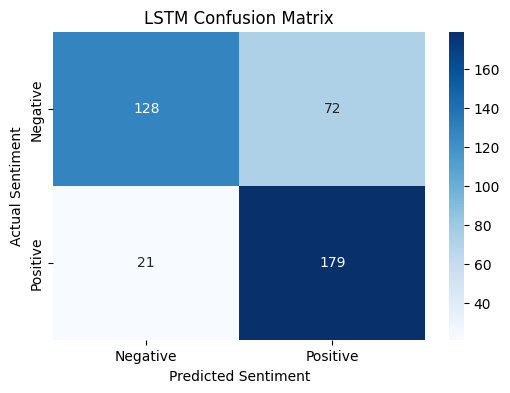

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Confusion Matrix")
plt.show()

In [37]:
def predict_sentiment(review):
    sequence = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Positive probability:", round(probability * 100, 2), "%")
    print("-" * 40)


predict_sentiment("The food was delicious and the service was excellent.")
predict_sentiment("The food was terrible and the staff were rude.")
predict_sentiment("The restaurant was good and the prices were reasonable.")

Review: The food was delicious and the service was excellent.
Predicted sentiment: Positive
Positive probability: 76.38 %
----------------------------------------
Review: The food was terrible and the staff were rude.
Predicted sentiment: Positive
Positive probability: 76.38 %
----------------------------------------
Review: The restaurant was good and the prices were reasonable.
Predicted sentiment: Positive
Positive probability: 76.38 %
----------------------------------------


In [38]:
import pickle

# Save the trained LSTM model
model.save("/content/zomato_sentiment_lstm.keras")

# Save the tokenizer
with open("/content/zomato_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [39]:
from google.colab import files

files.download("/content/zomato_sentiment_lstm.keras")
files.download("/content/zomato_tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

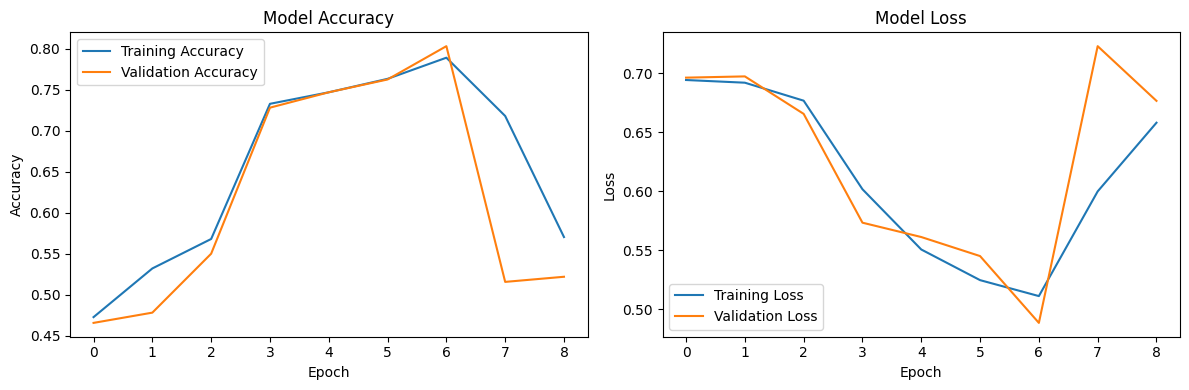

In [40]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print("Accuracy: ", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("Recall:   ", round(recall_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("F1-score: ", round(f1_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Accuracy:  76.75 %
Precision: 71.31 %
Recall:    89.5 %
F1-score:  79.38 %


In [41]:
import ipywidgets as widgets
from IPython.display import display, clear_output

review_input = widgets.Textarea(
    placeholder="Enter a restaurant review here...",
    description="Review:",
    layout=widgets.Layout(width="80%", height="100px")
)

predict_button = widgets.Button(
    description="Predict Sentiment",
    button_style="success"
)

output = widgets.Output()

def on_predict_clicked(button):
    with output:
        clear_output()

        review = review_input.value.strip()

        if not review:
            print("Please enter a review first.")
            return

        sequence = tokenizer.texts_to_sequences([review])
        padded = pad_sequences(
            sequence,
            maxlen=100,
            padding="post",
            truncating="post"
        )

        probability = float(model.predict(padded, verbose=0)[0][0])

        if probability >= 0.5:
            print("Predicted Sentiment: POSITIVE 😊")
        else:
            print("Predicted Sentiment: NEGATIVE 😞")

        print(f"Positive probability: {probability * 100:.2f}%")

predict_button.on_click(on_predict_clicked)

display(review_input, predict_button, output)


Textarea(value='', description='Review:', layout=Layout(height='100px', width='80%'), placeholder='Enter a res…

Button(button_style='success', description='Predict Sentiment', style=ButtonStyle())

Output()